# Perceptions of Corruption

> How do people perceive that there is corruption

# Imports

In [1]:
import matplotlib.pyplot as plt
from scipy import stats

from Q1_OLD_OLD.consts import *

from utils.read_csv_to_df import read_csv_to_df
from utils.plot_hist_with_normal_dist_overlay import plot_hist_with_normal_dist_overlay
from utils.rule_of_thumb__skewness import rule_of_thumb__skewness
from utils.rule_of_thumb__kurtosis import rule_of_thumb__kurtosis
from utils.plot_correlation_to_target import plot_correlation_to_target
from utils.preprocessing.transform import *

# Defaults

In [2]:
COLUMN = columns['POC']

# Fetch Data

In [3]:
train_df = read_csv_to_df(path=TRAIN_PATH)

# Summary

In [4]:
train_df[COLUMN].info()

PerceptionsOfCorruption_stats = train_df[[COLUMN]].describe().T

q1, q3 = train_df[COLUMN].quantile(0.25), train_df[COLUMN].quantile(0.75)
iqr = q3 - q1
PerceptionsOfCorruption_stats['IQR outliers'] = (
	(train_df[COLUMN] < q1 - 1.5 * iqr) | (train_df[COLUMN] > q3 + 1.5 * iqr)
).sum()

PerceptionsOfCorruption_stats

<class 'pandas.core.series.Series'>
RangeIndex: 1559 entries, 0 to 1558
Series name: Perceptions of corruption
Non-Null Count  Dtype  
--------------  -----  
1473 non-null   float64
dtypes: float64(1)
memory usage: 12.3 KB


,count,mean,std,min,25%,50%,75%,max,IQR outliers
Perceptions of corruption,1473.0,0.748248,0.186708,0.035,0.691,0.804,0.873,0.983,130


In [5]:
missing_values_PerceptionsOfCorruption = train_df[COLUMN].isna().sum()
count_PerceptionsOfCorruption = train_df[COLUMN].count()

print(f"{missing_values_PerceptionsOfCorruption} missing values out of {count_PerceptionsOfCorruption} -> {round(missing_values_PerceptionsOfCorruption / count_PerceptionsOfCorruption, 2)}%")

86 missing values out of 1473 -> 0.06%


# Plots

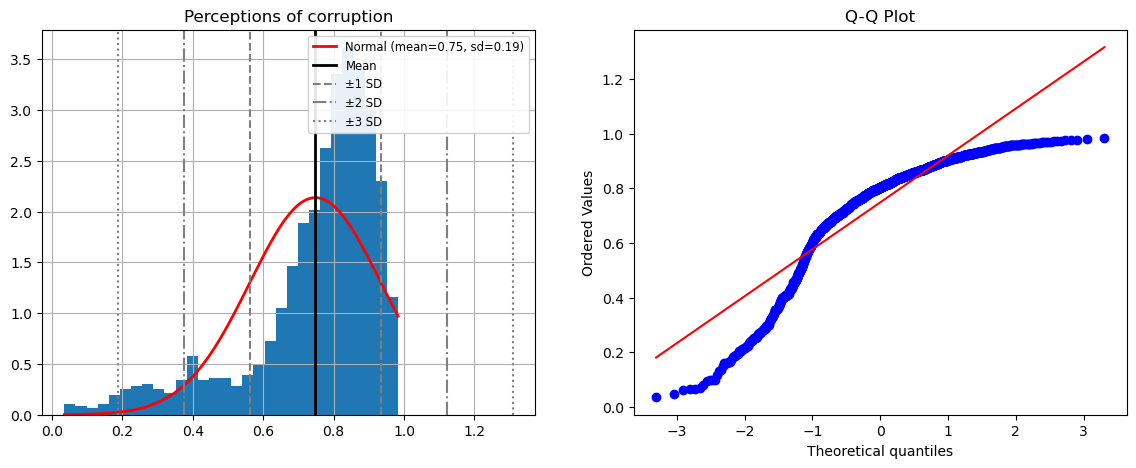

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plot_hist_with_normal_dist_overlay(
    series=train_df[COLUMN],
    bins=HIST_BINS,
    ax=ax1
)

stats.probplot(
	train_df[COLUMN].dropna(),
	dist="norm",
	plot=ax2)
ax2.set_title("Q-Q Plot")

plt.show()

# Correlation to Target

<Axes: title={'center': 'Life Ladder vs Perceptions of corruption'}, xlabel='Perceptions of corruption', ylabel='Life Ladder'>

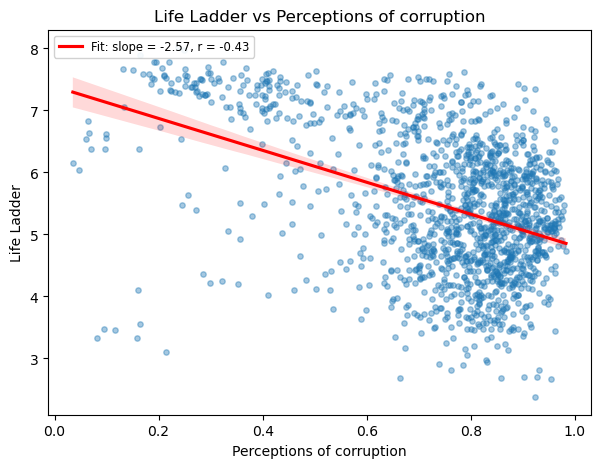

In [7]:
plot_correlation_to_target(
	df=train_df,
	feature="Perceptions of corruption",
	target=TARGET,
)

In [8]:
correlation_to_target_PerceptionsOfCorruption = train_df[TARGET].corr(train_df["Perceptions of corruption"])
print(f"Correlation: {correlation_to_target_PerceptionsOfCorruption:.3f}")

Correlation: -0.428


# Skew & Kurtosis

In [9]:
PerceptionsOfCorruptionSkew = train_df[COLUMN].skew()
PerceptionsOfCorruptionSkew_RuleOfThumb = rule_of_thumb__skewness(series=train_df["Perceptions of corruption"])
PerceptionsOfCorruptionKurtosis = train_df[COLUMN].kurt()
PerceptionsOfCorruptionKurtosis_RuleOfThumb = rule_of_thumb__kurtosis(series=train_df[COLUMN])

print(f'Perceptions of Corruption Skew: {PerceptionsOfCorruptionSkew:.3f} -> {PerceptionsOfCorruptionSkew_RuleOfThumb}')
print(f'Perceptions of Corruption Kurtosis: {PerceptionsOfCorruptionKurtosis:.3f} -> {PerceptionsOfCorruptionKurtosis_RuleOfThumb}')

Perceptions of Corruption Skew: -1.536 -> Highly skewed
Perceptions of Corruption Kurtosis: 2.006 -> Leptokurtic (heavy tails, more outliers)


In [10]:
PerceptionsOfCorruptionSkewTransformed = compare_all_transforms(series=train_df["Perceptions of corruption"])
PerceptionsOfCorruptionSkewTransformed

,skew_before,skew_after,skew_diff,kurt_before,kurt_after,kurt_diff,skew_rule_after
transform,,,,,,,
quantile,-1.536457,-0.001900,1.534557e+00,2.005973,0.663167,-1.342806e+00,Roughly symmetric
rank,-1.536457,-0.003395,1.533062e+00,2.005973,-1.201339,-3.207312e+00,Roughly symmetric
yeo_johnson,-1.536457,-0.294346,1.242110e+00,2.005973,-0.698718,-2.704691e+00,Roughly symmetric
cube,-1.536457,-0.388563,1.147894e+00,2.005973,-0.682955,-2.688928e+00,Roughly symmetric
box_cox,-1.536457,-0.478165,1.058292e+00,2.005973,-0.588753,-2.594726e+00,Roughly symmetric
logit,-1.536457,-0.805714,7.307424e-01,2.005973,1.266330,-7.396430e-01,Moderately skewed
square,-1.536457,-0.851109,6.853474e-01,2.005973,0.000455,-2.005519e+00,Moderately skewed
reflect_log,-1.536457,1.211801,2.748258e+00,2.005973,0.993836,-1.012137e+00,Highly skewed
arcsine_sqrt,-1.536457,-1.253410,2.830461e-01,2.005973,1.586488,-4.194853e-01,Highly skewed


---

### Notes / Observations
#### General
- 86 missing values (5.5% of rows), the most of any feature.
- A 0 to 1 score ranging from 0.04 to 0.98 (mean 0.75, median 0.80). Higher means more perceived corruption.
- The most skewed feature (skew -1.54) with heavy tails (kurtosis 2.01): most countries sit between 0.7 and 0.95, with a long flat tail down toward 0.
- 130 low IQR outliers (below about 0.42), about 9% of the column. These are a real group of low corruption countries, not data errors, so they should not be removed or clipped.
- Moderate negative link to happiness (r = -0.43): more corruption, less happiness.
- The scatter is L shaped, not a straight line. Low corruption countries (below 0.5) are mostly very happy, but above 0.6 happiness ranges from 2.5 to 7.5 with little trend.
- **Takeaway:** the signal comes mostly from the small group of low corruption countries, and the relationship is not linear.

#### Transforming
- Most in need of a transform: highly left skewed and leptokurtic.
- yeo_johnson works best while keeping magnitudes: skew -1.54 to -0.29, kurtosis 2.01 to -0.70.
- cube is close behind (skew -0.39); square is not enough (-0.85).
- log and sqrt make it much worse (-3.10, -2.10) because they stretch the low tail even further.
- rank is perfectly symmetric and handles the L shape well, but loses how far apart countries are.
- A transform fixes the shape of the column, but it will not turn the L shaped relationship into a straight line.
- **Pick:** yeo_johnson, fit on the train data only.

#### Scaling
- StandardScaler after the transform.
- Avoid MinMaxScaler on the raw values: the low outliers set the minimum, squeezing most countries into the top of the range.

#### Imputing
- The most missing of any feature, so the choice matters most here.
- Use the median (0.804), not the mean (0.748): the long low tail pulls the mean down.
- Only moderate links to other features (Freedom r = -0.48, GDP r = -0.34), so IterativeImputer helps a little.
- Worth adding a "was missing" indicator column so the model can learn if missing rows behave differently.